# TP2 · Clasificación supervisada — Bank Marketing
## Paso 4 · Modelo final

**Modelo elegido (Paso 3):** Random Forest con `max_depth = 10`, `n_estimators = 50`, set de variables B (14 variables). Tuvo el mejor ROC-AUC en validación cruzada (0.795), un gap train–validación chico (0.04), predicción rápida e importancia de variables interpretable.

**Orden de trabajo (para que el test siga siendo "datos nuevos"):**

| Etapa | Datos |
|---|---|
| 4.1 Elegir el **umbral de decisión** | Train: predicciones **fuera de fold** de la CV (Paso 3) |
| 4.2 **Estimar** la performance esperada | Train: CV (5 folds) con el umbral elegido |
| 4.3 Entrenar el modelo final | **Todo** train |
| 4.4 **Evaluar una única vez** | **Test** (20 %, nunca usado hasta acá) |

Todas las decisiones (variables, hiperparámetros, umbral) quedan **cerradas antes** de mirar el test.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (roc_curve, roc_auc_score, recall_score, precision_score,
                             confusion_matrix, f1_score)

from tp2_comun import (RANDOM_STATE, RESULTADOS, cargar_split, agregar_features, crear_preprocesador,
                       columnas, estilo_graficos, guardar, C_NO, C_YES, C_GRIS)
estilo_graficos()

SET = "B · EDA"
X_train, y_train = cargar_split("train")
Xtr = agregar_features(X_train)[columnas(SET)]
print("Train:", Xtr.shape, f"| % yes = {y_train.mean():.2%}")

def crear_modelo_final():
    return Pipeline([
        ("pre", crear_preprocesador(SET)),
        ("modelo", RandomForestClassifier(n_estimators=50, max_depth=10, random_state=RANDOM_STATE, n_jobs=-1)),
    ])
crear_modelo_final()

Train: (32940, 14) | % yes = 11.27%


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output 

### 4.1 Elección del umbral (solo con train)

El RF devuelve una **probabilidad** de `yes` (% de árboles que votan `yes`). Con el umbral por defecto (0.5) detectaba solo ~22 % de los interesados, porque como apenas el 11 % de los clientes acepta, muy pocos superan 0.5.

Como el error más grave es **perder un cliente interesado (FN)**, conviene **bajar el umbral**: sube el recall a cambio de más llamadas a clientes que no contratan (FP). Para elegirlo usamos el criterio visto en la clase 4: **el umbral cuyo punto (FPR, TPR) está más cerca del ideal (0, 1)** en la curva ROC.

**Datos usados:** las predicciones **fuera de fold** del RF ajustado (Paso 3). Cada cliente de train fue predicho por el modelo del fold que **no** lo usó para entrenar, así que el umbral se elige sobre predicciones "honestas" y **sin tocar el test**.

In [2]:
_, oof = joblib.load(RESULTADOS / "paso3_modelos_ajustados.joblib")
score_oof = oof["Random Forest"]["score"]
print(f"AUC fuera de fold (train): {roc_auc_score(y_train, score_oof):.3f}")

fpr, tpr, umbrales = roc_curve(y_train, score_oof)
dist = np.sqrt(fpr**2 + (1 - tpr)**2)          # distancia al punto ideal (0, 1)
i_opt = np.argmin(dist[1:]) + 1                # se descarta el primer umbral (= infinito)
UMBRAL = float(umbrales[i_opt])
print(f"Umbral elegido: {UMBRAL:.3f}  →  TPR (recall) = {tpr[i_opt]:.3f}, FPR = {fpr[i_opt]:.3f}, "
      f"distancia a (0,1) = {dist[i_opt]:.3f}")

# Punto del umbral por defecto, para comparar
i_05 = np.argmin(np.abs(umbrales - 0.5))

AUC fuera de fold (train): 0.794
Umbral elegido: 0.083  →  TPR (recall) = 0.681, FPR = 0.212, distancia a (0,1) = 0.383


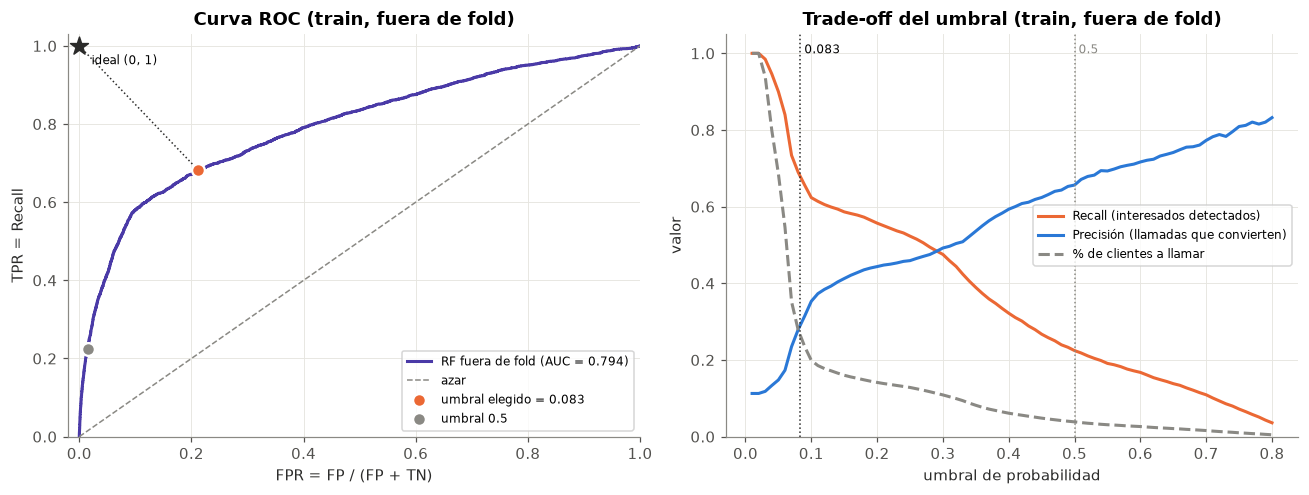

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

ax = axes[0]
ax.plot(fpr, tpr, color="#4a3aa7", lw=2, label=f"RF fuera de fold (AUC = {roc_auc_score(y_train, score_oof):.3f})")
ax.plot([0, 1], [0, 1], ls="--", color=C_GRIS, lw=1, label="azar")
ax.plot([0, fpr[i_opt]], [1, tpr[i_opt]], ls=":", color="#2b2b2a", lw=1)
ax.scatter([fpr[i_opt]], [tpr[i_opt]], s=70, color=C_YES, zorder=4, edgecolor="white", lw=1.5,
           label=f"umbral elegido = {UMBRAL:.3f}")
ax.scatter([fpr[i_05]], [tpr[i_05]], s=70, color=C_GRIS, zorder=4, edgecolor="white", lw=1.5, label="umbral 0.5")
ax.scatter([0], [1], marker="*", s=150, color="#2b2b2a", zorder=4)
ax.annotate("ideal (0, 1)", (0, 1), xytext=(8, -12), textcoords="offset points", fontsize=8)
ax.set(xlabel="FPR = FP / (FP + TN)", ylabel="TPR = Recall", title="Curva ROC (train, fuera de fold)", xlim=(-0.02, 1), ylim=(0, 1.03))
ax.legend(fontsize=8, loc="lower right")

ax = axes[1]
grid = np.linspace(0.01, 0.8, 80)
rec = [recall_score(y_train, score_oof >= u) for u in grid]
pre = [precision_score(y_train, score_oof >= u, zero_division=0) for u in grid]
llam = [(score_oof >= u).mean() for u in grid]
ax.plot(grid, rec, color=C_YES, lw=2, label="Recall (interesados detectados)")
ax.plot(grid, pre, color=C_NO, lw=2, label="Precisión (llamadas que convierten)")
ax.plot(grid, llam, color=C_GRIS, lw=2, ls="--", label="% de clientes a llamar")
ax.axvline(UMBRAL, color="#2b2b2a", lw=1, ls=":")
ax.axvline(0.5, color=C_GRIS, lw=1, ls=":")
ax.text(UMBRAL, 1.0, f" {UMBRAL:.3f}", fontsize=8); ax.text(0.5, 1.0, " 0.5", fontsize=8, color=C_GRIS)
ax.set(xlabel="umbral de probabilidad", ylabel="valor", title="Trade-off del umbral (train, fuera de fold)", ylim=(0, 1.05))
ax.legend(fontsize=8, loc="center right")
guardar("19_umbral")

**Umbral elegido: 0.083** (punto de la ROC más cercano a (0, 1): recall 0.68, FPR 0.21).

- Que el umbral sea tan bajo **tiene sentido**: la probabilidad base de `yes` es 11 %, así que un cliente con 8.3 % de probabilidad ya está cerca de la media. El umbral 0.5 exigiría que el modelo esté *muy* seguro y deja pasar casi todo.
- **Trade-off** (gráfico de la derecha): bajar de 0.5 a 0.083 hace pasar el recall de ~0.22 a ~0.68, a cambio de llamar a ~26 % de la base en lugar de ~4 %, y la precisión baja de ~0.65 a ~0.29.
- Ese costo es aceptable porque definimos que **perder un cliente interesado (FN) es más grave** que una llamada de más (FP).
- Por debajo de ~0.08 el % de clientes a llamar se dispara (la curva gris cae casi vertical), así que no conviene bajar más.

### 4.2 Performance esperada según la validación cruzada (train)
Con el umbral ya fijado, calculamos las métricas **en cada uno de los 5 folds de validación** (predicciones fuera de fold). La media ± desvío es nuestra **estimación** de lo que esperamos en datos nuevos.

In [4]:
FOLDS = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(Xtr, y_train))

def metricas(y, score, umbral):
    pred = (score >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {"ROC-AUC": roc_auc_score(y, score), "Recall": tp / (tp + fn), "Precisión": tp / (tp + fp),
            "Especificidad": tn / (tn + fp), "F1": f1_score(y, pred), "% a llamar": pred.mean()}

cv_folds = pd.DataFrame([metricas(y_train.iloc[va], score_oof[va], UMBRAL) for _, va in FOLDS])
estim_cv = cv_folds.agg(["mean", "std"]).T
estim_cv.columns = ["CV media", "CV desvío"]
estim_cv.round(3)

,CV media,CV desvío
ROC-AUC,0.795,0.008
Recall,0.681,0.012
Precisión,0.290,0.010
Especificidad,0.788,0.007
F1,0.406,0.011
% a llamar,0.265,0.005


### 4.3 Entrenamiento del modelo final con todo el train
El preprocesador (escalado + One-Hot) y el Random Forest se ajustan con las 32 940 filas de train. Se guarda el modelo en `resultados/modelo_final.joblib`.

In [5]:
modelo_final = crear_modelo_final().fit(Xtr, y_train)
joblib.dump({"modelo": modelo_final, "umbral": UMBRAL, "set": SET, "variables": columnas(SET)},
            RESULTADOS / "modelo_final.joblib")
print("Modelo final entrenado con", len(Xtr), "filas y guardado.")

Modelo final entrenado con 32940 filas y guardado.


### 4.4 Evaluación en test (una única vez)
A partir de acá **no se cambia ninguna decisión**: el test solo se usa para medir.

In [6]:
X_test, y_test = cargar_split("test")
Xte = agregar_features(X_test)[columnas(SET)]
score_test = modelo_final.predict_proba(Xte)[:, 1]
print("Test:", Xte.shape, f"| % yes = {y_test.mean():.2%}")

res_test = pd.Series(metricas(y_test, score_test, UMBRAL), name="Test")
res_test_05 = pd.Series(metricas(y_test, score_test, 0.5), name="Test (umbral 0.5, referencia)")
tabla = pd.concat([estim_cv, res_test, res_test_05], axis=1)
tabla.round(3)

Test: (8236, 14) | % yes = 11.27%


,CV media,CV desvío,Test,"Test (umbral 0.5, referencia)"
ROC-AUC,0.795,0.008,0.806,0.806
Recall,0.681,0.012,0.702,0.213
Precisión,0.290,0.010,0.303,0.647
Especificidad,0.788,0.007,0.795,0.985
F1,0.406,0.011,0.423,0.321
% a llamar,0.265,0.005,0.261,0.037


**Incertidumbre de la estimación en test (bootstrap).** El test es una muestra finita (8 236 clientes, ~930 `yes`). Para saber cuánto podría variar el resultado, se re-muestrea el test **con reemplazo** 1 000 veces (bootstrap, clase 7) y se recalculan las métricas → intervalo del 95 %. (El modelo y el umbral no cambian; solo se re-muestrean los clientes evaluados.)

In [7]:
rng = np.random.default_rng(RANDOM_STATE)
yt, st = y_test.to_numpy(), score_test
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    boot.append(metricas(yt[idx], st[idx], UMBRAL))
boot = pd.DataFrame(boot)
ic = boot.quantile([0.025, 0.975]).T
ic.columns = ["IC 95% inf", "IC 95% sup"]
final = pd.concat([estim_cv["CV media"], res_test.rename("Test"), ic], axis=1)
final.round(3)

,CV media,Test,IC 95% inf,IC 95% sup
ROC-AUC,0.795,0.806,0.789,0.823
Recall,0.681,0.702,0.674,0.731
Precisión,0.290,0.303,0.284,0.321
Especificidad,0.788,0.795,0.786,0.805
F1,0.406,0.423,0.401,0.444
% a llamar,0.265,0.261,0.251,0.270


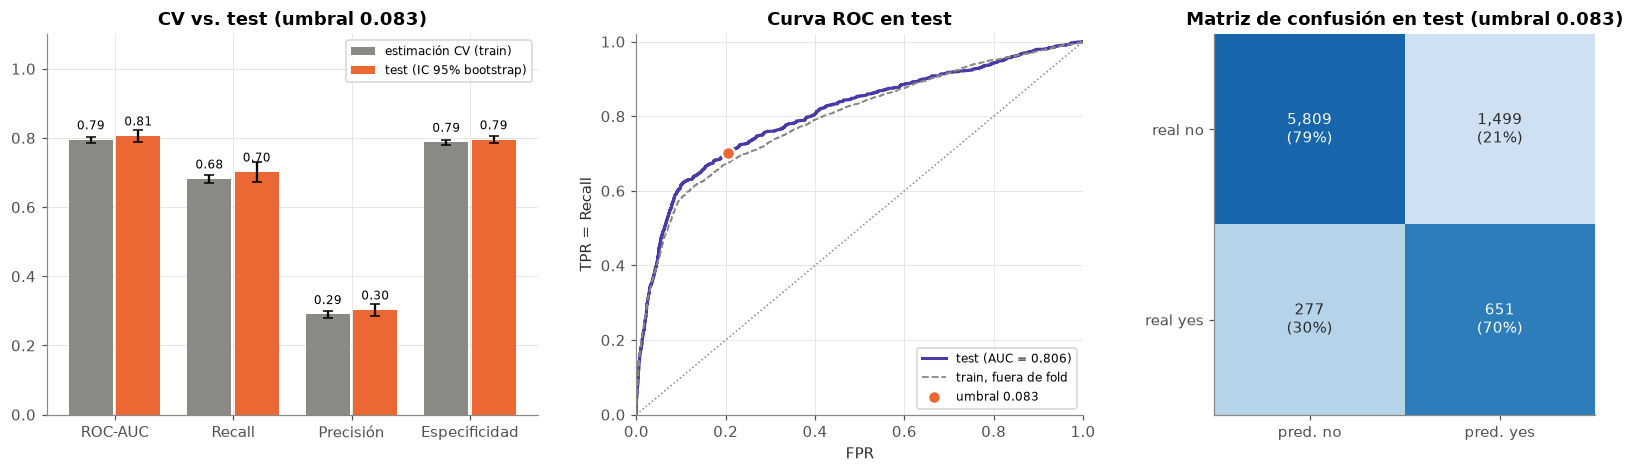

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.1, 1, 1]})

# (a) CV vs test para las métricas principales
ax = axes[0]
mets = ["ROC-AUC", "Recall", "Precisión", "Especificidad"]
x = np.arange(len(mets))
ax.bar(x - 0.2, estim_cv.loc[mets, "CV media"], width=0.37, yerr=estim_cv.loc[mets, "CV desvío"], capsize=3,
       color=C_GRIS, label="estimación CV (train)")
err = np.vstack([res_test[mets] - ic.loc[mets, "IC 95% inf"], ic.loc[mets, "IC 95% sup"] - res_test[mets]])
ax.bar(x + 0.2, res_test[mets], width=0.37, yerr=err, capsize=3, color=C_YES, label="test (IC 95% bootstrap)")
for xp, v in zip(x - 0.2, estim_cv.loc[mets, "CV media"]): ax.text(xp, v + 0.03, f"{v:.2f}", ha="center", fontsize=8)
for xp, v in zip(x + 0.2, res_test[mets]): ax.text(xp, v + 0.03, f"{v:.2f}", ha="center", fontsize=8)
ax.set_xticks(x, mets); ax.set(ylim=(0, 1.1), title=f"CV vs. test (umbral {UMBRAL:.3f})")
ax.legend(fontsize=8, loc="upper right")

# (b) ROC en test
ax = axes[1]
f_t, t_t, u_t = roc_curve(y_test, score_test)
ax.plot(f_t, t_t, color="#4a3aa7", lw=2, label=f"test (AUC = {roc_auc_score(y_test, score_test):.3f})")
ax.plot(fpr, tpr, color=C_GRIS, lw=1.2, ls="--", label="train, fuera de fold")
ax.plot([0, 1], [0, 1], ls=":", color=C_GRIS, lw=1)
cm = confusion_matrix(y_test, (score_test >= UMBRAL).astype(int)); tn, fp, fn, tp = cm.ravel()
ax.scatter([fp / (fp + tn)], [tp / (tp + fn)], s=70, color=C_YES, zorder=4, edgecolor="white", lw=1.5,
           label=f"umbral {UMBRAL:.3f}")
ax.set(xlabel="FPR", ylabel="TPR = Recall", title="Curva ROC en test", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(fontsize=8, loc="lower right")

# (c) matriz de confusión en test
ax = axes[2]
pct = cm / cm.sum(axis=1, keepdims=True)
ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n({pct[i, j]:.0%})", ha="center", va="center", fontsize=10,
                color="white" if pct[i, j] > 0.6 else "#2b2b2a")
ax.set_xticks([0, 1], ["pred. no", "pred. yes"]); ax.set_yticks([0, 1], ["real no", "real yes"])
ax.grid(False); ax.set_title(f"Matriz de confusión en test (umbral {UMBRAL:.3f})")
guardar("20_test_final")

**Resultado en test (evaluado una sola vez):**

| Métrica | Estimación CV (train) | **Test** | IC 95 % (bootstrap) |
|---|---|---|---|
| ROC-AUC | 0.795 ± 0.008 | **0.806** | 0.789 – 0.823 |
| Recall | 0.681 ± 0.012 | **0.702** | 0.674 – 0.731 |
| Precisión | 0.290 ± 0.010 | **0.303** | 0.284 – 0.321 |
| Especificidad | 0.788 ± 0.007 | **0.795** | 0.786 – 0.805 |

- **La estimación de la CV se confirma en test**: todos los valores de CV caen dentro del intervalo del 95 % del test. Esto valida el procedimiento: no hubo leakage ni sobreajuste a los datos de validación al elegir modelo, hiperparámetros y umbral.
- El test da apenas mejor que la CV. Es esperable: el modelo final se entrenó con el 100 % de train, mientras que cada modelo de la CV usó el 80 %.
- La curva ROC de test prácticamente se superpone a la de train fuera de fold.
- Con umbral 0.5 el mismo modelo tendría recall **0.21** en test: la elección del umbral triplica la cantidad de interesados detectados.

**Performance esperada en datos nuevos:** ROC-AUC ≈ **0.80** y recall ≈ **0.70** (entre 0.67 y 0.73), con precisión ≈ 0.30. *(Con la salvedad del contexto temporal discutida en el Paso 2: si la campaña futura ocurre en un contexto económico distinto, el desempeño podría ser menor.)*

### 4.5 ¿Qué significa para la campaña?

In [9]:
n, n_yes = len(y_test), int(y_test.sum())
llamadas = tp + fp
print(f"Clientes en test: {n:,}  |  interesados reales: {n_yes:,} ({n_yes/n:.1%})")
print(f"\nSin modelo (llamar a todos): {n:,} llamadas → {n_yes:,} contratos  |  tasa de éxito {n_yes/n:.1%}")
print(f"Con el modelo (umbral {UMBRAL:.3f}): {llamadas:,} llamadas ({llamadas/n:.0%} de la base) → "
      f"{tp:,} contratos ({tp/n_yes:.0%} de los interesados)  |  tasa de éxito {tp/llamadas:.1%}")
print(f"Interesados que se pierden (FN): {fn:,}")
print(f"\nCada llamada del modelo convierte {tp/llamadas / (n_yes/n):.1f} veces más que una llamada al azar.")

Clientes en test: 8,236  |  interesados reales: 928 (11.3%)

Sin modelo (llamar a todos): 8,236 llamadas → 928 contratos  |  tasa de éxito 11.3%
Con el modelo (umbral 0.083): 2,150 llamadas (26% de la base) → 651 contratos (70% de los interesados)  |  tasa de éxito 30.3%
Interesados que se pierden (FN): 277

Cada llamada del modelo convierte 2.7 veces más que una llamada al azar.


**Interpretación para el banco (test, 8 236 clientes):**
- **Sin modelo**, llamando a todos: 8 236 llamadas para 928 contratos (11.3 % de éxito).
- **Con el modelo**: se llama solo al **26 %** de la base (2 150 llamadas) y se consigue el **70 % de los contratos** (651). La tasa de éxito por llamada sube a **30.3 %**, es decir **2.7 veces** más que llamando al azar.
- **Costo:** se pierden 277 interesados (30 %), que son el error que más nos importa. Si el banco quisiera perder menos podría bajar el umbral, aceptando muchas más llamadas (ver el trade-off en 4.1).

### 4.6 Importancia de las variables
Importancia por **reducción de impureza** (Gini) acumulada en los árboles (clase 7). Las columnas One-Hot de una misma variable se suman para leer la importancia de la variable original.

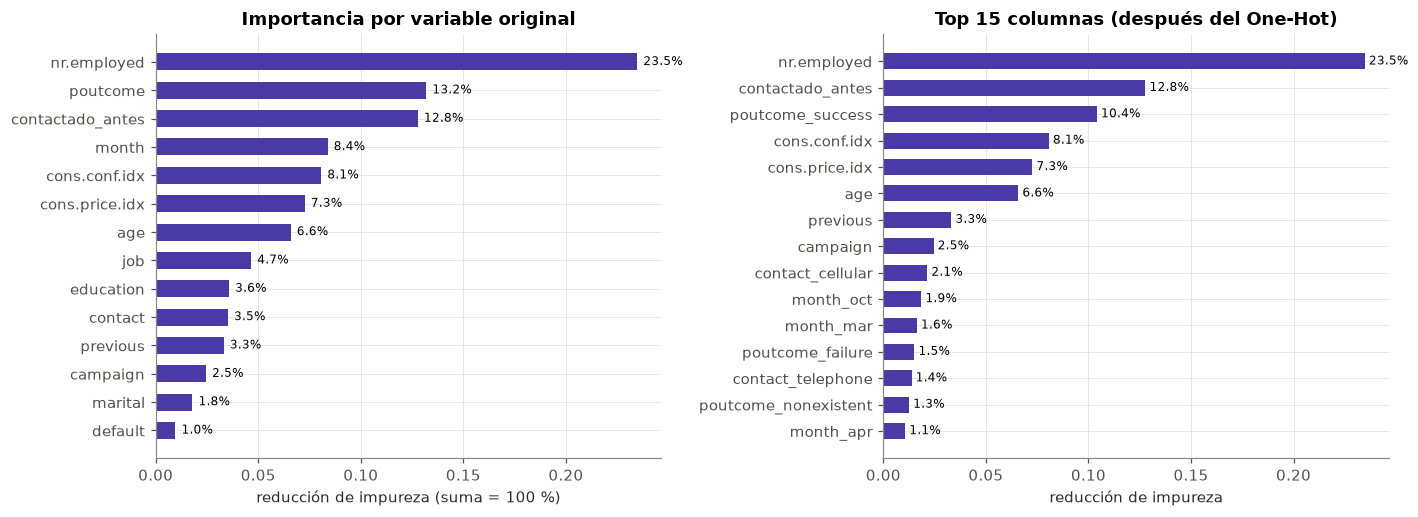

nr.employed         0.235
poutcome            0.132
contactado_antes    0.128
month               0.084
cons.conf.idx       0.081
cons.price.idx      0.073
age                 0.066
job                 0.047
education           0.036
contact             0.035
previous            0.033
campaign            0.025
marital             0.018
default             0.010
dtype: float64

In [10]:
pre, rf = modelo_final.named_steps["pre"], modelo_final.named_steps["modelo"]
nombres = pre.get_feature_names_out()
imp = pd.Series(rf.feature_importances_, index=nombres)
original = imp.groupby(lambda c: next(v for v in columnas(SET) if c.split("__", 1)[1] == v
                                      or c.split("__", 1)[1].startswith(v + "_"))).sum().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
ax.barh(original.index, original.values, color="#4a3aa7", height=0.6)
for i, v in enumerate(original.values): ax.text(v + 0.003, i, f"{v:.1%}", va="center", fontsize=8)
ax.set(title="Importancia por variable original", xlabel="reducción de impureza (suma = 100 %)")
ax = axes[1]
top = imp.sort_values().tail(15)
ax.barh([c.split("__", 1)[1] for c in top.index], top.values, color="#4a3aa7", height=0.6)
for i, v in enumerate(top.values): ax.text(v + 0.002, i, f"{v:.1%}", va="center", fontsize=8)
ax.set(title="Top 15 columnas (después del One-Hot)", xlabel="reducción de impureza")
guardar("21_importancia_variables")
original.sort_values(ascending=False).round(3)

**Lectura:**
- **Contexto temporal / económico ≈ 47 %** (`nr.employed` 23.5 %, `month` 8.4 %, `cons.conf.idx` 8.1 %, `cons.price.idx` 7.3 %). Es coherente con el Paso 2: sin estas variables el AUC caía ~0.08. El modelo aprende mucho sobre *cuándo* llamar.
- **Historial de campañas previas ≈ 29 %** (`poutcome` 13.2 %, `contactado_antes` 12.8 %, `previous` 3.3 %). `poutcome_success` y `contactado_antes` se reparten la misma información (la redundancia detectada en el EDA): para RF no es un problema, pero "infla" el total de ese grupo.
- **Perfil del cliente ≈ 24 %** (`age` 6.6 %, `job` 4.7 %, `education` 3.6 %, `contact` 3.5 %, `campaign` 2.5 %, `marital`, `default`).
- *(Ojo: la importancia por impureza tiende a favorecer variables numéricas con muchos valores posibles frente a categóricas partidas en varias columnas binarias.)*

### 4.7 Conclusión del Paso 4

1. **Modelo final:** Random Forest (`max_depth = 10`, `n_estimators = 50`, set B de 14 variables) con **umbral 0.083**, elegido solo con train (criterio del punto más cercano a (0, 1) de la ROC).
2. **Performance esperada en datos nuevos** (confirmada en test): **ROC-AUC ≈ 0.80** y **recall ≈ 0.70**, con precisión ≈ 0.30.
3. **Valor práctico:** llamando al 26 % de los clientes se captura el 70 % de los interesados, con una tasa de éxito por llamada 2.7 veces mayor que sin modelo.
4. **La CV fue una buena estimación:** todos los valores caen dentro del intervalo del 95 % del test, lo que respalda que el pipeline (split previo, transformaciones dentro del `Pipeline`, decisiones solo con train) no tuvo leakage.
5. **Limitaciones** (para las conclusiones finales): casi la mitad de la importancia viene del contexto económico y del mes, así que el desempeño en una campaña futura con otro contexto puede ser menor; además, se sigue perdiendo un 30 % de los interesados.